# Checkpoint 3 — Clustering aplicado à energia

**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Integrantes:** Gabriel Savoy — RM 568991; Victor Vidigal — RM 571318; Raphael Tien — RM 570261.  
**Turma:** 1CCA.

## Situação-problema

Uma equipe de gestão de energia quer conhecer os diferentes perfis de uso de suas unidades consumidoras para planejar ações de acompanhamento e uso consciente de energia. Cada registro reúne informações de uma unidade no mesmo mês de referência.

Seu desafio é identificar grupos de unidades com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 unidades consumidoras fictícias**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de medidores, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_unidade` | Identificador da unidade consumidora | Identificação; excluir do modelo |
| `consumo_mensal_kwh` | Energia total consumida no mês | kWh |
| `demanda_maxima_kw` | Maior demanda de potência média registrada em uma janela de 15 minutos no mês | kW |
| `consumo_noturno_pct` | Parcela da energia mensal consumida entre 18h e 6h | % entre 0 e 100 |

Energia, em kWh, representa o consumo acumulado; potência, em kW, representa a taxa de uso de energia. O percentual noturno descreve o horário de consumo. Nenhuma dessas variáveis, isoladamente, permite afirmar que uma unidade desperdiça energia ou que paga uma tarifa maior.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
UC001,791.43,7.28,23.95
UC002,1349.44,6.65,72.17
UC003,1355.67,6.5,76.47
UC004,209.34,0.5,67.76
UC005,1675.8,5.99,78.53
UC006,259.28,3.13,59.3
UC007,180.39,3.38,61.37
UC008,1705.73,8.78,76.28
UC009,1421.17,6.34,66.16
UC010,769.67,8.28,13.51
UC011,1003.9,6.81,24.07
UC012,1136.69,5.5,39.81
UC013,1237.83,5.41,28.87
UC014,1358.74,4.78,26.72
UC015,696.34,7.57,32.59
UC016,330.75,1.83,64.99
UC017,1448.43,6.91,69.18
UC018,1559.32,4.87,75.15
UC019,208.86,2.98,79.31
UC020,1340.84,5.18,51.64
UC021,1666.35,6.22,54.65
UC022,684.26,7.29,21.61
UC023,1858.04,6.28,57.13
UC024,1548.18,5.13,76.59
UC025,1286.54,7.4,70.44
UC026,671.62,6.18,27.59
UC027,286.11,1.74,71.6
UC028,306.77,2.73,70.48
UC029,191.95,2.71,46.75
UC030,160.72,3.07,46.56
UC031,1914.05,6.29,67.69
UC032,639.82,5.55,22.34
UC033,1343.78,5.82,71.13
UC034,199.73,2.95,66.44
UC035,1466.32,6.83,59.17
UC036,166.38,2.19,58.04
UC037,754.59,11.69,30.64
UC038,256.47,1.57,61.37
UC039,1440.36,5.28,72.3
UC040,1112.84,10.02,30.37
UC041,1325.72,7.23,65.96
UC042,1244.96,7.05,61.76
UC043,1580.58,8.86,61.86
UC044,288.92,3.5,48.41
UC045,1413.1,5.86,73.32
UC046,1243.79,9.36,74.18
UC047,1018.37,8.09,16.74
UC048,889.65,7.82,20.83
UC049,293.69,2.78,49.17
UC050,239.89,2.61,50.72
UC051,1149.27,4.41,69.7
UC052,903.31,6.04,47.47
UC053,1447.32,7.0,60.31
UC054,324.49,3.43,57.92
UC055,975.35,7.83,24.91
UC056,253.75,3.19,47.61
UC057,185.26,2.79,60.37
UC058,275.33,2.06,76.62
UC059,1173.41,8.29,27.67
UC060,336.68,1.44,61.73
UC061,1472.11,5.42,56.01
UC062,1420.31,5.76,69.66
UC063,1066.74,7.03,8.35
UC064,1206.7,4.49,65.74
UC065,301.5,2.46,62.06
UC066,471.96,4.72,22.2
UC067,793.83,6.47,39.74
UC068,814.11,8.18,20.03
UC069,1083.2,6.04,24.84
UC070,835.44,8.55,26.43
UC071,191.85,1.84,50.14
UC072,541.54,5.65,23.23
UC073,266.76,2.93,58.84
UC074,234.77,3.06,73.52
UC075,1070.5,6.15,25.14
UC076,1270.27,3.3,71.85
UC077,212.02,2.76,59.79
UC078,1426.91,6.37,54.31
UC079,226.26,2.13,63.17
UC080,130.01,2.74,56.49
UC081,695.66,3.84,37.71
UC082,1599.27,5.34,49.98
UC083,1357.57,3.68,74.87
UC084,1373.33,6.77,90.34
UC085,504.17,6.68,39.48
UC086,328.86,3.42,65.21
UC087,1134.59,7.04,73.45
UC088,194.57,2.38,72.45
UC089,945.97,5.09,17.76
UC090,1441.73,6.74,44.47
UC091,1524.46,6.97,78.07
UC092,714.84,8.2,13.75
UC093,1379.84,6.47,64.98
UC094,1108.56,5.36,64.45
UC095,210.07,2.21,54.13
UC096,1174.74,5.89,18.89
UC097,644.55,6.99,27.88
UC098,208.74,2.93,67.23
UC099,1873.16,4.36,64.23
UC100,1138.21,7.79,24.51
UC101,270.96,2.2,62.31
UC102,784.72,9.76,32.76
UC103,1237.88,4.97,79.03
UC104,841.88,7.37,15.06
UC105,1362.73,3.61,63.05
UC106,666.95,7.15,17.58
UC107,1136.73,2.2,26.42
UC108,222.53,2.76,69.93
UC109,206.28,2.32,43.43
UC110,197.03,3.69,59.72
UC111,294.74,2.25,70.32
UC112,319.74,2.93,55.82
UC113,379.07,2.13,61.4
UC114,305.26,3.2,52.56
UC115,868.46,7.37,24.69
UC116,147.71,2.36,67.72
UC117,606.83,6.35,21.84
UC118,1382.92,9.14,68.61
UC119,967.14,7.18,29.84
UC120,874.2,5.62,21.92
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Unidades consumidoras: {len(df)}")


id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47
     UC004              209.34               0.50                67.76
     UC005             1675.80               5.99                78.53
Unidades consumidoras: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o consumo mensal poderia esconder diferenças de comportamento?


In [3]:
print('Dimensões:', df.shape)
print('\nTipos das colunas:')
df.info()
print('\nValores ausentes por coluna:')
print(df.isna().sum().to_string())
print('\nIDs duplicados:', df['id_unidade'].duplicated().sum())
print('\nEstatísticas descritivas:')
display(df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']].describe().round(2))
print('\nAmplitude (máximo - mínimo):')
print((df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']].max() - df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']].min()).round(2))

Dimensões: (120, 4)

Tipos das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_unidade           120 non-null    object 
 1   consumo_mensal_kwh   120 non-null    float64
 2   demanda_maxima_kw    120 non-null    float64
 3   consumo_noturno_pct  120 non-null    float64
dtypes: float64(3), object(1)
memory usage: 3.9+ KB

Valores ausentes por coluna:
id_unidade             0
consumo_mensal_kwh     0
demanda_maxima_kw      0
consumo_noturno_pct    0

IDs duplicados: 0

Estatísticas descritivas:


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
count,120.00,120.00,120.00
mean,851.84,5.20,51.23
std,516.24,2.30,20.39
min,130.01,0.50,8.35
25%,294.48,2.97,29.60
50%,855.17,5.46,57.98
75%,1341.57,6.98,67.73
max,1914.05,11.69,90.34



Amplitude (máximo - mínimo):
consumo_mensal_kwh     1784.04
demanda_maxima_kw        11.19
consumo_noturno_pct      81.99
dtype: float64


**Resposta e observações:**

A base possui **120 linhas e 4 colunas**, sendo um identificador textual e três variáveis numéricas. **Não há valores ausentes nem identificadores repetidos**. As amplitudes são **1.784,04 kWh** para consumo mensal (130,01 a 1.914,05), **11,19 kW** para demanda máxima (0,50 a 11,69) e **81,99 pontos percentuais** para consumo noturno (8,35% a 90,34%). A maior amplitude numérica é a do consumo mensal, mas as unidades de medida são diferentes e não permitem comparar dispersões diretamente. Usar somente kWh esconderia diferenças na potência máxima demandada e na proporção do consumo entre 18h e 6h: duas unidades com energia mensal semelhante podem ter picos e horários de uso distintos.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_unidade` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [4]:
variaveis = ['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']
X = df[variaveis].copy()  # exclui id_unidade
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)
print('Formato de X:', X.shape, '| formato padronizado:', X_padronizado.shape)
display(pd.DataFrame(X_padronizado, columns=variaveis).head().round(3))
print('Médias após padronização:', np.round(X_padronizado.mean(axis=0), 6))
print('Desvios-padrão após padronização:', np.round(X_padronizado.std(axis=0), 6))

Formato de X: (120, 3) | formato padronizado: (120, 3)


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
0,-0.118,0.907,-1.343
1,0.968,0.633,1.031
2,0.980,0.567,1.243
3,-1.250,-2.051,0.814
4,1.603,0.345,1.344


Médias após padronização: [-0. -0. -0.]
Desvios-padrão após padronização: [1. 1. 1.]


**Justificativa da padronização:**

O K-Means utiliza distâncias euclidianas. Sem padronização, a escala numérica do consumo em kWh dominaria as distâncias, reduzindo a influência de demanda (kW) e percentual noturno (%). O `StandardScaler` subtrai a média e divide pelo desvio-padrão de cada variável, colocando-as em escalas comparáveis (média próxima de zero e desvio-padrão próximo de um). **Não** limita os valores ao intervalo de 0 a 1. Os dados originais continuam preservados em `df` para interpretação.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, consumos de 100, 120 e 140 kWh formam um grupo com centroide de 120 kWh. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800\;\mathrm{kWh}^2$$

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa kWh consumidos. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


,k,inercia
0,1,360.000
1,2,184.696
2,3,74.253
3,4,61.103
4,5,52.062
5,6,46.362
6,7,40.896
7,8,37.246


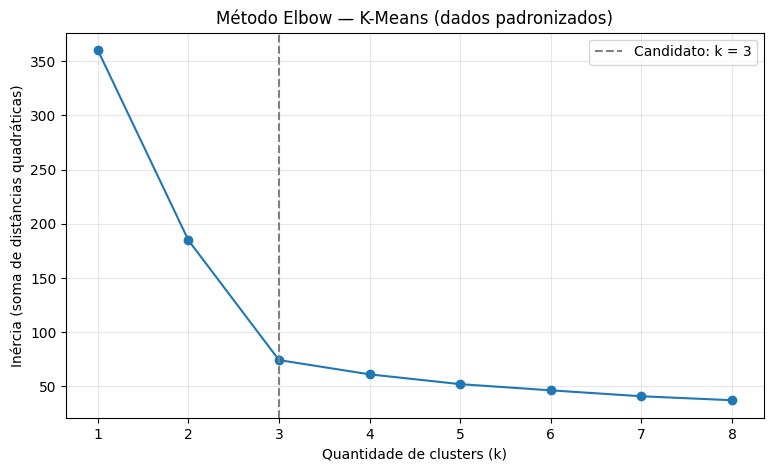

In [5]:
valores_k = list(range(1, 9))
distorcoes = []
for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

display(pd.DataFrame({'k': valores_k, 'inercia': distorcoes}).round(3))
plt.figure(figsize=(9, 5))
plt.plot(valores_k, distorcoes, marker='o')
plt.axvline(3, linestyle='--', color='gray', label='Candidato: k = 3')
plt.xticks(valores_k)
plt.title('Método Elbow — K-Means (dados padronizados)')
plt.xlabel('Quantidade de clusters (k)')
plt.ylabel('Inércia (soma de distâncias quadráticas)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Leitura do Elbow:**

A inércia cai de **360,00 (k=1)** para **184,70 (k=2)** e **74,25 (k=3)**. Depois, cai apenas para **61,10 (k=4)** e **52,06 (k=5)**. Assim, a redução de k=2 para k=3 é de aproximadamente **110,44**, enquanto de k=3 para k=4 é de **13,15**. O cotovelo aparece próximo de **k=3**: a partir daí, acrescentar clusters traz ganhos de compactação bem menores. A inércia sempre tende a diminuir quando k cresce, então esse gráfico sozinho não decide o melhor k.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


,k,silhouette
0,2,0.4835
1,3,0.6031
2,4,0.5190
3,5,0.4282
4,6,0.4343
5,7,0.3240
6,8,0.3106


Melhor score: k=3, Silhouette=0.6031


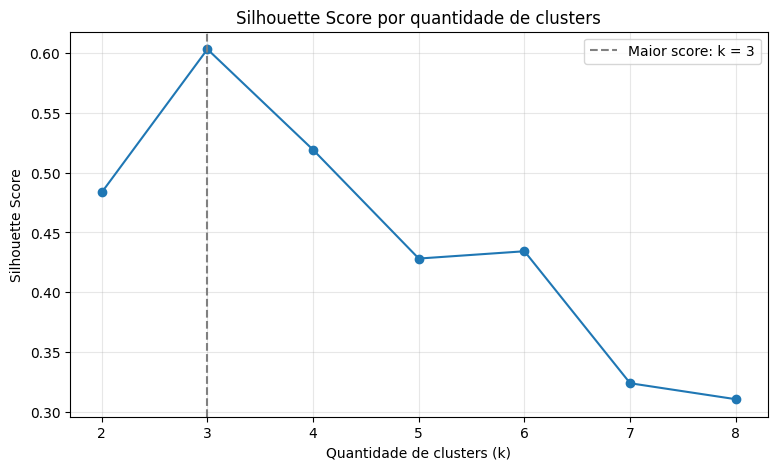

In [6]:
resultados_silhouette = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    resultados_silhouette.append({'k': k, 'silhouette': silhouette_score(X_padronizado, rotulos)})
tabela_silhouette = pd.DataFrame(resultados_silhouette)
display(tabela_silhouette.round(4))
melhor_linha = tabela_silhouette.loc[tabela_silhouette['silhouette'].idxmax()]
print(f"Melhor score: k={int(melhor_linha['k'])}, Silhouette={melhor_linha['silhouette']:.4f}")
plt.figure(figsize=(9, 5))
plt.plot(tabela_silhouette['k'], tabela_silhouette['silhouette'], marker='o')
plt.axvline(3, linestyle='--', color='gray', label='Maior score: k = 3')
plt.xticks(range(2, 9))
plt.xlabel('Quantidade de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score por quantidade de clusters')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Comparação das evidências:**

O maior Silhouette Score ocorre em **k=3 (0,6031)**, superior a **k=2 (0,4835)** e **k=4 (0,5190)**. Para k=5, 6, 7 e 8, os scores são aproximadamente **0,4282; 0,4343; 0,3240; 0,3106**, respectivamente. O Elbow também indica k próximo de 3, pois a inércia passa de 184,70 (k=2) a 74,25 (k=3), mas a melhoria seguinte é menor. Portanto, **ambos os métodos convergem para k=3**, que também permite interpretar três perfis distintos. Silhouette mede coesão/separação, não porcentagem de acertos.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de unidades por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [7]:
k_escolhido = 3
modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)
df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais
print('Quantidade de unidades por cluster:')
display(df_resultados['cluster'].value_counts().sort_index().rename_axis('cluster').reset_index(name='unidades'))
score_final = silhouette_score(X_padronizado, rotulos_finais)
print(f'Silhouette Score final: {score_final:.4f}')

Quantidade de unidades por cluster:


,cluster,unidades
0,0,40
1,1,40
2,2,40


Silhouette Score final: 0.6031


**k escolhido e justificativa:**

Escolhemos **k=3**. O gráfico Elbow mostra um cotovelo em k=3 (inércia **74,25**, contra **184,70** para k=2 e **61,10** para k=4). Além disso, o maior Silhouette Score testado é **0,6031** em k=3. O modelo final identifica **40 unidades em cada cluster**, com perfis interpretáveis de consumo intermediário e menor participação noturna, consumo baixo e consumo alto com participação noturna elevada. Os rótulos 0, 1 e 2 são arbitrários e não representam uma classificação de qualidade.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Consumo mensal × demanda máxima.
2. Consumo mensal × percentual de consumo noturno.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de unidades e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de gestão de energia para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Consumo alto não prova desperdício. Uma recomendação sobre tarifa ou geração solar exigiria dados adicionais de contrato, horários, local e viabilidade.


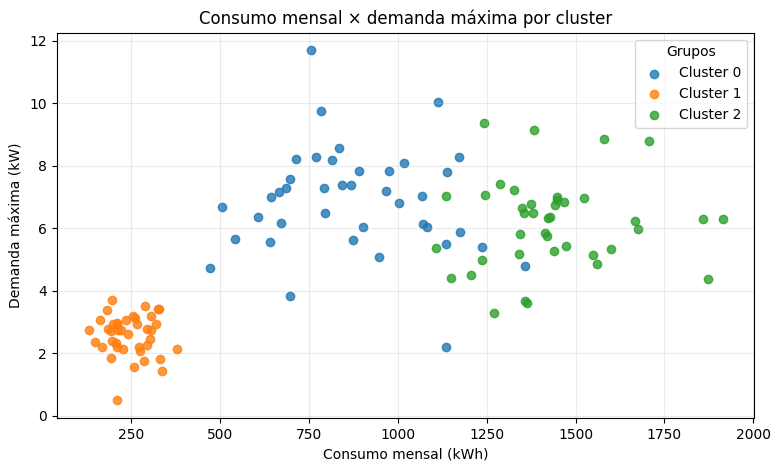

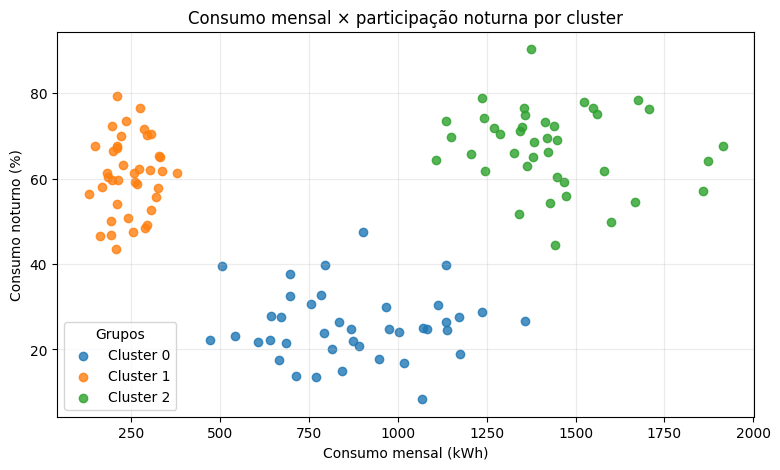

Observação: os gráficos são projeções em 2D; o K-Means foi treinado com 3 variáveis.


In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for cluster, grupo in df_resultados.groupby('cluster'):
    ax.scatter(grupo['consumo_mensal_kwh'], grupo['demanda_maxima_kw'], label=f'Cluster {cluster}', alpha=0.8)
ax.set(title='Consumo mensal × demanda máxima por cluster', xlabel='Consumo mensal (kWh)', ylabel='Demanda máxima (kW)')
ax.legend(title='Grupos')
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for cluster, grupo in df_resultados.groupby('cluster'):
    ax.scatter(grupo['consumo_mensal_kwh'], grupo['consumo_noturno_pct'], label=f'Cluster {cluster}', alpha=0.8)
ax.set(title='Consumo mensal × participação noturna por cluster', xlabel='Consumo mensal (kWh)', ylabel='Consumo noturno (%)')
ax.legend(title='Grupos')
ax.grid(alpha=0.25)
plt.show()
print('Observação: os gráficos são projeções em 2D; o K-Means foi treinado com 3 variáveis.')

In [9]:
tabela_perfis = df_resultados.groupby('cluster').agg(
    unidades=('id_unidade', 'count'),
    consumo_medio_kwh=('consumo_mensal_kwh', 'mean'),
    demanda_media_kw=('demanda_maxima_kw', 'mean'),
    noturno_medio_pct=('consumo_noturno_pct', 'mean')
).reset_index()
display(tabela_perfis.round(2))

,cluster,unidades,consumo_medio_kwh,demanda_media_kw,noturno_medio_pct
0,0,40,876.50,6.87,25.49
1,1,40,245.09,2.58,60.82
2,2,40,1433.93,6.15,67.37


**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| **0** | **40 unidades**; média de **876,50 kWh**, **6,87 kW** de demanda máxima e **25,49%** de consumo noturno. Perfil de consumo intermediário, com demanda relativamente alta e menor participação noturna. | Monitorar os horários de pico e avaliar escalonamento de equipamentos para reduzir coincidência de cargas, se viável. | Curva de carga em intervalos de 15 min, equipamentos em operação e requisitos do processo. |
| **1** | **40 unidades**; média de **245,09 kWh**, **2,58 kW** de demanda e **60,82%** de consumo noturno. Perfil de menor consumo e demanda, com parcela noturna relevante. | Acompanhar o uso noturno e oferecer orientações de eficiência para iluminação e equipamentos, após verificar a origem desse consumo. | Equipamentos, ocupação, horários de funcionamento e histórico de consumo. |
| **2** | **40 unidades**; média de **1.433,93 kWh**, **6,15 kW** de demanda e **67,37%** de consumo noturno. Perfil de alto consumo mensal e elevada participação noturna. | Priorizar auditoria energética e levantamento dos usos noturnos para identificar oportunidades de eficiência sem prejudicar a operação. | Atividade da unidade, medições horárias, equipamentos, contrato tarifário e histórico. |

**Interpretação responsável:** os dados mostram padrões de consumo e demanda, **não comprovam desperdício**, custos elevados ou inadequação tarifária. Recomendações de tarifa ou energia solar dependeriam de dados adicionais de contrato, localização, horários e viabilidade técnica/econômica.

## 8. Conclusão — 1,0 ponto

**Conclusão:**

1. **Utilidade para a gestão:** o agrupamento separa 120 unidades em três perfis, ajudando a priorizar monitoramento de picos (cluster 0), orientação e investigação de usos noturnos em unidades de baixo consumo (cluster 1) e auditorias nas unidades de consumo elevado (cluster 2). Isso permite ações mais direcionadas, sem tratar todas as unidades como iguais.
2. **Por que não escolher só pela menor inércia?** A inércia diminui à medida que k aumenta, inclusive quando se criam divisões pouco úteis. É necessário observar o cotovelo, a separação entre grupos e a interpretabilidade. Aqui, a inércia é 74,25 em k=3 e 37,25 em k=8, mas k=8 tem Silhouette inferior.
3. **Por que Silhouette não é acurácia?** Não existem rótulos verdadeiros na base. O índice mede quão próximos os pontos estão do próprio grupo em comparação com outros grupos, e não a porcentagem de classificações corretas.
4. **Por que separar `cluster` das entradas?** A coluna `cluster` é uma saída do algoritmo. Usá-la como entrada alteraria artificialmente as distâncias e produziria avaliação circular. O identificador também não descreve comportamento energético e deve ficar fora do modelo.
5. **Limitações e próximos dados:** a base é **simulada**, contém apenas **120 unidades** e representa **um único mês**, portanto os perfis não podem ser generalizados automaticamente para consumidores reais. Além disso, o K-Means usa distâncias euclidianas, é sensível a outliers e pressupõe grupos relativamente compactos; médias mensais não mostram picos detalhados ou sazonalidade. Para melhorar a análise, seriam necessários dados reais de medidores em intervalos de 15 minutos, vários meses, tipo de atividade, área/ocupação, equipamentos, horários operacionais, tarifas e condições climáticas. Seria importante também verificar estabilidade dos clusters e valores atípicos.

**Síntese:** **k=3** foi sustentado conjuntamente pelo Elbow e pelo maior Silhouette Score (**0,6031**). Os resultados sugerem ações de gestão, mas **não demonstram causalidade nem desperdício**.

## Entrega e critérios de avaliação

Entregue o **notebook `.ipynb` preenchido e executado**, contendo identificação, códigos, tabelas, gráficos, justificativas e conclusões. A base está incorporada; não é necessário um arquivo externo para executar a atividade. Prazo e canal de entrega serão definidos pelo professor.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,0 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade inspirada na sequência do notebook de referência fornecido pelo professor, com nova base de energia e cuidados adicionais na seleção e avaliação das variáveis.
